# After controlling for age, marital status, and group affiliation, does the probability and velocity of primary online radicalization among lone-actor terrorists increase significantly in the post-algorithmic era (2011–2022) compared to the pre-algorithmic era (1999–2010)?

repo: https://github.com/gentemannraymadi01/cs82a-portfolio

Background: Algorithms became more commonly used to rank and recommend content on major social media platforms in the early 2010s. For example, Facebook changed its ranking system around 2011 (source: https://www.newamerica.org/oti/reports/rising-through-ranks/news-feed-ranking/) and YouTube changed its recommendation system in 2012 (source: https://www.newamerica.org/oti/reports/why-am-i-seeing-this/case-study-youtube). This notebook uses 2011 as a rough dividing line.

This notebook does not show that algorithms caused any change. It compares the percent of lone offenders primarily radicalized online and speed of radicalization across two groups, 1999-2010 and 2011-2022.

## Data source

**Dataset:** Profiles of Individual Radicalization in the United States (PIRUS), Version 5, accessed October 2026

**Citation:** National Consortium for the Study of Terrorism and Responses to Terrorism (START), University of Maryland. (2023). Profiles of Individual Radicalization in the United States (PIRUS) [Data file]. Retrieved from http://www.start.umd.edu/data-tools/profiles-individual-radicalization-united-states-pirus
Copyright University of Maryland 2023

**License:** Used in accordance with START's End User License Agreement under non-commercial academic research use. The raw data and codebook are not in this notebook. Any changes to the data are documented in the cleaning log.

**To run:** download PIRUS V5 from START and save it as `PIRUS V5.xlsx`

In [1]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint
warnings.filterwarnings("ignore")
os.makedirs("figures", exist_ok=True)

BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 11})

df = pd.read_excel("PIRUS V5.xlsx")

In [2]:
log = [("Load raw PIRUS V5", len(df), "one row per individual")]

d = df[df["Lone_Offender"] == 1].copy()
log.append(("Keep lone offenders", len(d), "Lone_Offender == 1"))

n_old = (d["Year_Exposure"] < 1999).sum()
d = d[d["Year_Exposure"] >= 1999].copy()
log.append(("Keep exposure year >= 1999", len(d), f"dropped {n_old}; internet variable is not applicable before 1999"))

d["era"] = (d["Year_Exposure"] >= 2011).astype(int)
d["era_label"] = np.where(d.era == 1, "2011-2022", "1999-2010")
log.append(("Define era", len(d), f"pre n={(d.era == 0).sum()}, post n={(d.era == 1).sum()}"))

cols = ["Age", "Marital_Status", "Group_Membership", "Internet_Radicalization", "Rad_duration"]
unk = {c: int((d[c] == -99).sum()) for c in cols}
d[cols] = d[cols].replace(-99, np.nan)
log.append(("Recode -99 (unknown) to missing", len(d), ", ".join(f"{k}={v}" for k, v in unk.items())))

# Outcome 1: internet was the PRIMARY means of radicalization (code 2)
d["prim_online"] = np.where(d.Internet_Radicalization.isna(), np.nan, (d.Internet_Radicalization == 2).astype(float))
# Outcome 2 (velocity): radicalized in under 1 year (Rad_duration code 1)
d["fast"] = np.where(d.Rad_duration.isna(), np.nan, (d.Rad_duration == 1).astype(float))

# Controls
d["marital"] = d.Marital_Status.map({1: "single", 2: "married", 3: "div_sep", 4: "div_sep"})  # widowed merged (n=9)
d["group"] = d.Group_Membership.map({0: "none", 1: "aboveground", 2: "informal", 3: "formal_or_movement"})
log.append(("Build outcomes and controls", len(d), "prim_online, fast (<1yr), marital (widowed merged), group labels"))

cc = d.dropna(subset=["prim_online", "Age", "marital", "group"])
log.append(("Complete cases, main model", len(cc), f"primary-online events = {int(cc.prim_online.sum())}"))

pd.set_option("display.max_colwidth", 120, "display.width", 200)
pd.DataFrame(log, columns=["step", "rows", "detail"])

,step,rows,detail
0,Load raw PIRUS V5,3528,one row per individual
1,Keep lone offenders,1165,Lone_Offender == 1
2,Keep exposure year >= 1999,1091,dropped 74; internet variable is not applicable before 1999
3,Define era,1091,"pre n=107, post n=984"
4,Recode -99 (unknown) to missing,1091,"Age=14, Marital_Status=248, Group_Membership=11, Internet_Radicalization=384, Rad_duration=493"
5,Build outcomes and controls,1091,"prim_online, fast (<1yr), marital (widowed merged), group labels"
6,"Complete cases, main model",607,primary-online events = 140


In [3]:
d.groupby("era_label").agg(
    n=("Subject_ID", "size"),
    internet_role_unknown=("Internet_Radicalization", lambda s: s.isna().mean()),
    duration_unknown=("Rad_duration", lambda s: s.isna().mean())).round(3)

,n,internet_role_unknown,duration_unknown
era_label,,,
1999-2010,107,0.607,0.495
2011-2022,984,0.324,0.447


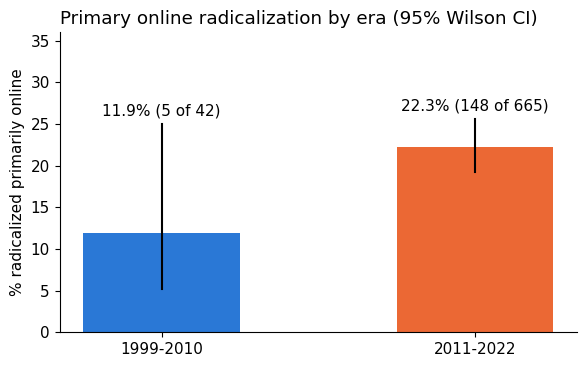

In [4]:
k = d.dropna(subset=["prim_online"])
fig, ax = plt.subplots(figsize=(6, 3.8))
for i, (lab, g) in enumerate(k.groupby("era_label")):
    x, n = int(g.prim_online.sum()), len(g)
    p, (lo, hi) = x / n, proportion_confint(x, n, method="wilson")
    ax.bar(i, p * 100, color=[BLUE, ORANGE][i], width=0.5)
    ax.plot([i, i], [lo * 100, hi * 100], color="black", lw=1.5)
    ax.text(i, hi * 100 + 1, f"{p*100:.1f}% ({x} of {n})", ha="center")
ax.set_xticks([0, 1]); ax.set_xticklabels(["1999-2010", "2011-2022"]); ax.set_ylim(0, 36)
ax.set_ylabel("% radicalized primarily online")
ax.set_title("Primary online radicalization by era (95% Wilson CI)", loc="left")
fig.tight_layout(); fig.savefig("figures/fig1_share.png", dpi=200); plt.show()

### Chart 1 takeaway
Chart 1 includes every lone offender with a known online radicalization status. The percent of lone offenders radicalized primarily online is higher in the 2011-2022 (22.3%) group compared to the 1999-2010 (11.9%) group. The 1999-2010 group is smaller. This is why the error bar for that group is longer.

In [5]:
F = 'era + Age + C(marital, Treatment("single")) + C(group, Treatment("none"))'

def fit(label, data, y="prim_online"):
    dd = data.dropna(subset=[y, "Age", "marital", "group"])
    m = smf.logit(f"{y} ~ {F}", dd).fit(disp=0, cov_type="HC1")
    ci = m.conf_int().loc["era"]
    ame = m.get_margeff(at="overall", dummy=True).summary_frame().loc["era"]
    return dict(spec=label, n=len(dd), events=int(dd[y].sum()),
                OR=np.exp(m.params["era"]), lo=np.exp(ci[0]), hi=np.exp(ci[1]), p=m.pvalues["era"],
                AME=ame["dy/dx"] * 100)

main = fit("Main model", d)
print(f"Era OR = {main['OR']:.2f} (95% CI {main['lo']:.2f}-{main['hi']:.2f}), p = {main['p']:.3f}, "
      f"average effect = {main['AME']:+.1f} percentage points")
print(cc.groupby("era_label").prim_online.agg(events="sum", n="count"))

Era OR = 3.30 (95% CI 1.00-10.84), p = 0.049, average effect = +15.0 percentage points
           events    n
era_label             
1999-2010     3.0   33
2011-2022   137.0  574


### Missing Data Takeaway
For 60.7% of lone offenders the role of the internet in radicalization is unknown in 1999-2010, vs 32.4% in 2011-2022. The percent of unknown radicalization duration is closer at 49.5% in the earlier group and 44.7% in the later. The main model only references cases with complete data. The comparison between 1999-2010 and 2011-2022 could be biased if the unknown cases differ from the known ones. The analysis cannot tell us in which direction. It can tell us how uncertain the sampling is, as shown by the error bars and p-values.

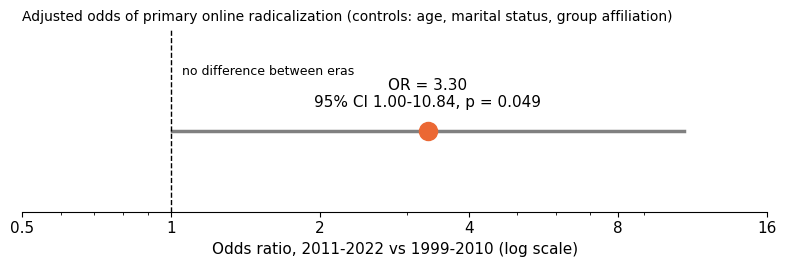

In [6]:
fig, ax = plt.subplots(figsize=(8, 2.8))

ax.plot([main["lo"], main["hi"]], [0, 0], color="grey", lw=2.5)
ax.plot(main["OR"], 0, "o", ms=13, color=ORANGE)
ax.axvline(1, color="black", ls="--", lw=1)
ax.text(1.05, 0.55, "no difference between eras", fontsize=9, color="black")
ax.text(main["OR"], 0.2,
        f"OR = {main['OR']:.2f}\n95% CI {main['lo']:.2f}-{main['hi']:.2f}, p = {main['p']:.3f}",
        ha="center", va="bottom")

ax.set_xscale("log"); ax.set_xlim(0.5, 16); ax.set_ylim(-0.8, 1)
ax.set_xticks([0.5, 1, 2, 4, 8, 16]); ax.set_xticklabels(["0.5", "1", "2", "4", "8", "16"])
ax.set_yticks([]); ax.spines["left"].set_visible(False)
ax.set_xlabel("Odds ratio, 2011-2022 vs 1999-2010 (log scale)")
ax.set_title("Adjusted odds of primary online radicalization (controls: age, marital status, group affiliation)", loc="left", fontsize=10)

fig.tight_layout(); fig.savefig("figures/fig2_main_model.png", dpi=200, bbox_inches="tight"); plt.show()

### Chart 2 Takeaway
After controlling for age, marital status, and group affiliation, the odds of being radicalized primarily online are about 3.3 times higher in 2011-2022 than in 1999-2010, as represented by the orange dot. Chart 2 only includes the 607 offenders who also have known age, marital status, and group affiliation, so its rates are slightly different from Chart 1's (9.1% in 1999-2010 and 23.9% in 2011-2022, compared with 11.9% and 22.3%). The 1999-2010 group has only 3 cases of primarily online radicalization. The result is statistically significant (p = 0.049), but it is imprecise, as represented by the wide grey bar. Because of the small sample and borderline p-value, these results should be read as suggestive, not conclusive.

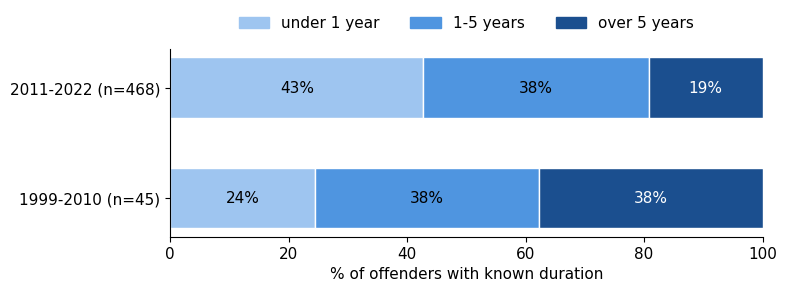

Under-1-year OR = 2.33 (95% CI 1.17-4.65), p = 0.0167, average effect = +17.6 percentage points (n=513)


In [7]:
v = d.dropna(subset=["Rad_duration", "Age", "marital", "group"])
mix = pd.crosstab(v.era_label, v.Rad_duration, normalize="index") * 100
names = {1: "under 1 year", 2: "1-5 years", 3: "over 5 years"}
cols_ = {1: "#9ec5f0", 2: "#4f95e0", 3: "#1b4f8f"}

fig, ax = plt.subplots(figsize=(8, 3.2))
for yi, era in enumerate(["1999-2010", "2011-2022"]):
    left = 0
    for dur in [1, 2, 3]:
        w = mix.loc[era, dur]
        ax.barh(yi, w, left=left, color=cols_[dur], height=0.55, edgecolor="white")
        ax.text(left + w / 2, yi, f"{w:.0f}%", ha="center", va="center", color="white" if dur == 3 else "black")
        left += w
ax.set_yticks([0, 1]); ax.set_yticklabels([f"{e} (n={(v.era_label == e).sum()})" for e in ["1999-2010", "2011-2022"]])
ax.set_xlim(0, 100); ax.set_xlabel("% of offenders with known duration")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=cols_[i]) for i in [1, 2, 3]], [names[i] for i in [1, 2, 3]],
          ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.25), frameon=False)
fig.tight_layout(); fig.savefig("figures/fig3_velocity.png", dpi=200, bbox_inches="tight"); plt.show()

fast = fit("Radicalized in under 1 year", d, y="fast")
print(f"Under-1-year OR = {fast['OR']:.2f} (95% CI {fast['lo']:.2f}-{fast['hi']:.2f}), p = {fast['p']:.4f}, "
      f"average effect = {fast['AME']:+.1f} percentage points (n={fast['n']})")

### Chart 3 takeaway

People in the 2011-2022 group were more likely to be radicalized faster than those in the 1999-2010 group. 24% were radicalized in under a year before 2011, after 2011 this increases to 43%. After controlling for age, marital status, and group affiliation, the odds of radicalizing in under one year were about 2.3 times higher (OR = 2.33, 95% CI 1.17-4.65, p = 0.017). This shows a statistically significant association.

## Limitations
This notebook does not prove causation. It is not proof that algorithms caused a change in radicalization method or velocity. It compares two time periods meant to represent the before and after of widespread algorithm use in media recommendation and platforms changed at different times (Facebook around 2011, YouTube 2012), so the 2011 cutoff is rough. In the earlier group 60.7% of cases have an unknown internet role vs 32.4% later, while error bars and p-values do represent the uncertainty caused by this the direction of any bias is not known. After controlling for other factors the early group is small, with only 3 primary-online cases in the 1999-2010 group, while the p = 0.049 is still technically statistically significant the result is borderline and should be read as suggestive. Also the velocity result could be biased. Because people in the later group have had less time to offend(2011-2022 < 1999-2022), people who radicalize slowly may have not offended yet. That data bias could contribute to the later era looking faster.

## Conclusions
Primary online radicalization was more common in 2011-2022 (22.3% vs 11.9%). After controlling for age, marital status, and group affiliation, the odds were roughly 3.3 times higher (p = 0.049). Because of the small early group and close p-value, these results are suggestive not conclusive. In regards to velocity, the proportion of people radicalized in under a year rose from 24% to 43%. Adjusted odds were about 2.3 times higher (p = 0.017). Again because people in that group have had less time to offend, people who radicalize slowly may have not offended yet and that data bias could make the later era look faster. The rates of primarily online radicalization and the proportion of people who radicalized in under a year both increased in the later group. This does not prove causation.

## Ethics
No names or identifying information were used in this notebook. The dataset is built from public open source records and has no direct identifiers. The raw data and codebook are not redistributed. The repo has instructions for downloading them.